In [14]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as mcm
from astropy.io import fits
import pandas as pd
import astropy.wcs as wcs
from astropy.coordinates import SkyCoord
from matplotlib.patches import Rectangle
from astropy import units as u
import time as tm

import skyproj
import lsst.geom as geom
from lsst.daf.butler import Butler
from lsst.rsp import get_tap_service

plt.style.use('./presentation.mplstyle')

In [2]:
butler = Butler("dp1", collections="LSSTComCam/DP1") #Instantiate the butler.
assert butler is not None

skymap = butler.get("skyMap") #Define the skymap.
username = os.environ.get('USER')

sample = pd.read_csv('goods_selection.csv')
print(sample.shape)

(14701, 4)


In [4]:
service = get_tap_service("tap")
assert service is not None

query = "SELECT lsst_tract,lsst_patch,s_ra,s_dec, s_region " \
        "FROM dp1.CoaddPatches " 
results = service.search(query).to_table().to_pandas()
print(results.shape)

(652, 5)


In [6]:
results['s_reg_list'] = results['s_region'].str.findall(r'[-+]?\d*\.?\d+')
regions = pd.DataFrame(results['s_reg_list'].to_list(), columns=['ra1','dec1','ra2','dec2','ra3','dec3','ra4','dec4']).astype(float)

In [7]:
coordList = [geom.SpherePoint(src['ra'], src['dec'], geom.degrees) for ii,src in sample.iterrows()]
tractPatchList = skymap.findTractPatchList(coordList)

In [8]:
patchlist = []
for tractPatch in tractPatchList:
    tract = tractPatch[0]
    patchInfo = tractPatch[1]
    for patch in patchInfo:
        print(tract.tract_id, patch.sequential_index)
        patchlist.append(patch.sequential_index)

5063 23
5063 33
5063 43
5063 24
5063 34
5063 44
5063 25
5063 35
5063 45


In [10]:
#sel = (results['s_dec']<-27.5) & (results['s_dec']>-28.7) & (results['s_ra']<54.0) & (results['s_ra']>52.25)
sel = (results['lsst_tract']==5063)&(results['lsst_patch'].isin(patchlist))
print(results[sel].shape)
#sel = (results['s_dec']<-27.7) & (results['s_dec']>-27.9) & (results['s_ra']<53.3) & (results['s_ra']>53.1)
#print(results[sel])

(9, 6)


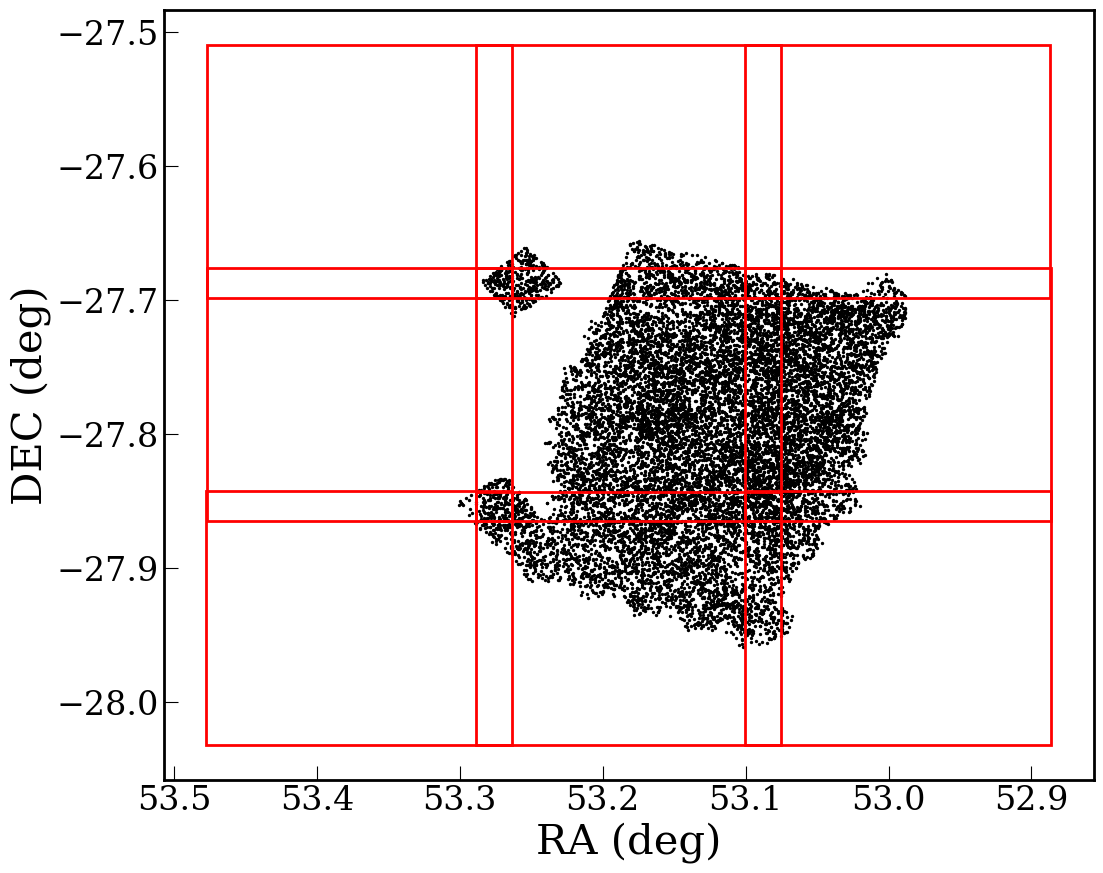

In [15]:
fig,ax=plt.subplots(figsize=(12,10))

#ax.pcolormesh(x, y, values)
im = ax.scatter(sample['ra'],sample['dec'],s=2,c='black')
for ii, src in regions[sel].iterrows():
    rect = Rectangle((src['ra1'], src['dec1']), src['ra2']-src['ra1'], src['dec4']-src['dec1'], linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect)

ax.set_rasterized(True)

ax.set_xlabel(r"RA (deg)",fontsize=30)
ax.set_ylabel(r"DEC (deg)",fontsize=30)
#plt.colorbar(im, label=r"PSF Mag Limit (r-band)")
plt.gca().invert_xaxis()

plt.savefig('ECDFS_map.pdf',bbox_inches='tight')

plt.show()

In [12]:
data_list = []
for ii, src in sample.iterrows():
    point = geom.SpherePoint(src['ra'] * geom.degrees,src['dec'] * geom.degrees)
    tract = skymap.findTract(point)
    patch = tract.findPatch(point)
    
    data_list.append({"objid":int(src['id']),"ra": np.round(src['ra'],6), "dec": np.round(src['dec'],6),"tract":tract.tract_id,"patch":patch.getSequentialIndex(),"zspec":src['z_best']})
    #tract_number,patch_number = tract.tract_id,patch.getSequentialIndex()
    #print(ii,ra,dec,tract_number,patch_number)
df = pd.DataFrame(data_list)

In [13]:
df.to_csv("v1sdwarf_list.csv", index=False)